# FPCA vs FAE simulation
Linear and nonlinear settings, $K\in\{3,5,7\}$, $B\in\{10,\dots,50\}$, 100 replications.

In [1]:
%%writefile sim_core.py
from __future__ import annotations
import math
from dataclasses import dataclass, asdict
import numpy as np
import torch
torch.set_num_threads(1)

def bspline_basis(n_basis: int, n_time: int, degree: int=3) -> np.ndarray:
    tau = np.linspace(0.0, 1.0, n_time)
    p = degree
    n_int = max(n_basis - p - 1, 0)
    interior = np.linspace(0.0, 1.0, n_int + 2)[1:-1] if n_int > 0 else np.array([])
    knots = np.concatenate((np.zeros(p + 1), interior, np.ones(p + 1)))
    N = np.zeros((n_basis, n_time))
    for i in range(n_basis):
        N[i] = np.where((tau >= knots[i]) & (tau < knots[i + 1]), 1.0, 0.0)
    N[-1, tau == 1.0] = 1.0
    for k in range(1, p + 1):
        Nn = np.zeros_like(N)
        for i in range(n_basis):
            dl = knots[i + k] - knots[i]
            left = (tau - knots[i]) / dl * N[i] if dl > 0 else 0.0
            right = 0.0
            if i + 1 < n_basis:
                dr = knots[i + k + 1] - knots[i + 1]
                if dr > 0:
                    right = (knots[i + k + 1] - tau) / dr * N[i + 1]
            Nn[i] = left + right
        N = Nn
    return N.T

def trapezoid_weights(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, float)
    dx = np.diff(x)
    w = np.empty_like(x)
    w[0], w[-1] = (dx[0] / 2, dx[-1] / 2)
    w[1:-1] = (x[2:] - x[:-2]) / 2
    return w

@dataclass
class SimCfg:
    seed: int = 123
    T: int = 500
    P: int = 100
    d: int = 5
    Sigma_scale: float = 0.028
    meas_noise_sd: float = 0.001
    age_min: float = 15.0
    age_max: float = 49.0
    fertility_tail_strength: float = 0.012
    shift_scale: float = 0.14
    dilation_scale: float = 0.18
    warp_scale: float = 0.08
    peak_width: float = 0.08
    shoulder_width: float = 0.12
    trend_scale: float = 1.0
    trend_mode: str = 'det+ar1'
    trend_rho: float = 0.995
    trend_sd: float = 0.577
    clip_value: float = 2.0
    latent_rho: float = 0.0
    nonlin_scale: float = 1.0
    drift_coef: float = 0.05
    latent_gain: float = 1.0
    map_mode: str = 'nonlinear'
    lin_n_basis: int = 12
    lin_target_rho: float = 0.85
    lin_weight_sd: float = 0.8
    lin_exact_rho: bool = False
    lin_d: int = 0
    burnin: int = 0

def _latent_A(cfg: SimCfg) -> np.ndarray:
    A = np.array([[0.6, 0.05, 0.0, 0.0, 0.0], [0.0, 0.72, 0.06, 0.0, 0.0], [0.0, 0.0, 0.66, 0.05, 0.0], [0.0, 0.0, 0.0, 0.68, 0.06], [0.03, 0.0, 0.0, 0.0, 0.62]])[:cfg.d, :cfg.d]
    if cfg.latent_rho > 0:
        A = A - np.diag(np.diag(A)) + cfg.latent_rho * np.eye(cfg.d)
    return A

def _latent_step(z, t, A, eps, cfg: SimCfg):
    T = cfg.T
    tau = t / max(T - 1, 1)
    drift = np.array([-0.25 * (tau - 0.5), 1.1 * (tau - 0.5), 0.25 * np.sin(2 * np.pi * tau), 0.2 * np.sin(np.pi * tau), 0.15 * np.cos(2 * np.pi * tau)])
    z0, z1, z2, z3, z4 = (z[..., i] for i in range(5))
    g = np.stack([0.1 * np.tanh(z1) - 0.04 * np.tanh(0.8 * z0 * z1), 0.18 * np.tanh(z2) + 0.04 * np.tanh(z0 ** 2), -0.1 * np.tanh(z0) + 0.08 * np.tanh(0.8 * z3), 0.08 * np.sin(np.clip(z1, -3, 3)) + 0.04 * np.tanh(0.6 * z2 * z3), 0.06 * np.tanh(0.8 * z4) + 0.03 * np.tanh(0.6 * z1 * z2)], -1)
    return np.clip(z @ A.T + cfg.nonlin_scale * g + cfg.drift_coef * drift + eps, -cfg.clip_value, cfg.clip_value)

def _latent_nonlinear(cfg: SimCfg) -> np.ndarray:
    rng = np.random.default_rng(cfg.seed)
    d, T = (cfg.d, cfg.T)
    Sigma = cfg.Sigma_scale ** 2 * np.eye(d)
    A = _latent_A(cfg)
    Z = np.zeros((T, d))
    Z[0] = rng.multivariate_normal(np.zeros(d), Sigma)
    for t in range(1, T):
        eps = rng.multivariate_normal(np.zeros(d), Sigma)
        Z[t] = _latent_step(Z[t - 1], t, A, eps, cfg)
    return Z

def oracle_forecast(cfg: SimCfg, L: int=5, n_mc: int=400, seed: int=0):
    Z = _latent_nonlinear(cfg)
    T0 = cfg.T - L
    rng = np.random.default_rng(seed)
    A = _latent_A(cfg)
    z = np.repeat(Z[T0 - 1][None], n_mc, 0)
    out = []
    for h in range(L):
        t = T0 + h
        z = _latent_step(z, t, A, rng.normal(size=z.shape) * cfg.Sigma_scale, cfg)
        tr_t = np.full(n_mc, np.linspace(-1, 1, cfg.T)[t])
        out.append(_decoder_nonlinear(z, cfg, tr=tr_t).mean(0))
    return np.array(out)

def trend_path(cfg: SimCfg) -> np.ndarray:
    if cfg.trend_mode == 'det':
        return np.linspace(-1, 1, cfg.T)
    if cfg.trend_mode == 'det+ar1':
        return np.linspace(-1, 1, cfg.T) + trend_path(SimCfg(**{**cfg.__dict__, 'trend_mode': 'ar1'}))
    r = np.random.default_rng(cfg.seed + 555)
    tr = np.empty(cfg.T)
    tr[0] = cfg.trend_sd * r.normal()
    e = cfg.trend_sd * np.sqrt(1 - cfg.trend_rho ** 2) * r.normal(size=cfg.T)
    for t in range(1, cfg.T):
        tr[t] = cfg.trend_rho * tr[t - 1] + e[t]
    return tr

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

def _decoder_nonlinear(Z: np.ndarray, cfg: SimCfg, tr=None) -> np.ndarray:
    T = Z.shape[0]
    u = np.linspace(0, 1, cfg.P)[None, :]
    if tr is None:
        tr = np.linspace(-1, 1, T)
    tr = cfg.trend_scale * tr
    Z = cfg.latent_gain * Z
    z1, z2, z3, z4, z5 = (Z[:, i] for i in range(5))
    z1 = z1 - 0.2 * tr
    z2 = z2 + 1.0 * tr
    amp = 0.07 + 0.07 * _sig(z1 - 0.6 * z2)
    sh_amp = 0.16 * _sig(1.1 * z4 + 0.5 * z5)
    tail_amp = cfg.fertility_tail_strength * _sig(1.1 * z5 + 0.5 * z4)
    shift = cfg.shift_scale * np.tanh(1.4 * z2 - 0.7 * z3 + 0.3 * z1 * z4)[:, None]
    dil = 1.0 + cfg.dilation_scale * np.tanh(1.1 * z3 + 0.3 * z5)[:, None]
    lw = cfg.warp_scale * np.tanh(1.3 * z4 - 0.6 * z2 + 0.2 * z1 * z5)[:, None] * np.exp(-0.5 * ((u - 0.48) / 0.16) ** 2) * np.sin(np.pi * (u - 0.15))
    us = np.clip(0.5 + (u - shift + lw - 0.5) / dil, -0.2, 1.2)
    main = np.exp(-0.5 * ((us - 0.38) / cfg.peak_width) ** 2)
    shoulder = np.exp(-0.5 * ((us - 0.58) / cfg.shoulder_width) ** 2)
    tail = _sig((us - 0.62) / 0.04) * np.exp(-np.clip(us - 0.62, 0, None) / 0.13)
    X = amp[:, None] * main + (sh_amp * amp)[:, None] * shoulder + tail_amp[:, None] * tail
    return np.clip(X, 0.0, None)

def _linear_benchmark(cfg: SimCfg) -> np.ndarray:
    rng = np.random.default_rng(cfg.seed)
    d, T = (cfg.lin_d or cfg.d, cfg.T)
    Sigma = cfg.Sigma_scale ** 2 * np.eye(d)
    A = rng.normal(size=(d, d)) * 0.15
    rho = np.max(np.abs(np.linalg.eigvals(A)))
    if (cfg.lin_exact_rho or rho > cfg.lin_target_rho) and rho > 1e-12:
        A = A * (cfg.lin_target_rho / rho)
    Tb = T + cfg.burnin
    Z = np.zeros((Tb, d))
    Z[0] = rng.multivariate_normal(np.zeros(d), Sigma)
    for t in range(1, Tb):
        Z[t] = A @ Z[t - 1] + rng.multivariate_normal(np.zeros(d), Sigma)
    Z = Z[cfg.burnin:]
    rw = np.random.default_rng(cfg.seed + 7)
    W1 = rw.normal(size=(d, 20)) * cfg.lin_weight_sd
    W2 = rw.normal(size=(20, cfg.lin_n_basis)) * cfg.lin_weight_sd
    Bg = bspline_basis(cfg.lin_n_basis, cfg.P)
    return Z @ W1 @ W2 @ Bg.T

def simulate(cfg: SimCfg):
    if cfg.map_mode == 'nonlinear':
        Xc = _decoder_nonlinear(_latent_nonlinear(cfg), cfg, tr=trend_path(cfg))
    else:
        Xc = _linear_benchmark(cfg)
    rng = np.random.default_rng(cfg.seed + 999)
    Xn = Xc + cfg.meas_noise_sd * rng.normal(size=Xc.shape)
    u = np.linspace(cfg.age_min, cfg.age_max, cfg.P) if cfg.map_mode == 'nonlinear' else np.linspace(0.0, 1.0, cfg.P)
    return (u, Xc.astype(np.float64), Xn.astype(np.float64))

def rel_mse(xhat, xref):
    return float(np.mean((xhat - xref) ** 2) / max(np.var(xref), 1e-300))

def fit_var1(H, ridge=1e-06):
    X = np.hstack([np.ones((len(H) - 1, 1)), H[:-1]])
    Y = H[1:]
    Bm = np.linalg.solve(X.T @ X + ridge * np.eye(X.shape[1]), X.T @ Y)
    return (Bm[0], Bm[1:].T)

def forecast_var1(h_last, b, A, steps):
    out, h = ([], h_last.copy())
    for _ in range(steps):
        h = b + A @ h
        out.append(h)
    return np.array(out)

def fpca_B(Xtr: np.ndarray, u: np.ndarray, K: int, B: int, steps: int, ridge=1e-06):
    Phi = bspline_basis(B, Xtr.shape[1])
    S = Phi @ np.linalg.solve(Phi.T @ Phi, Phi.T)
    Xs = Xtr @ S.T
    w = trapezoid_weights(u)
    sw = np.sqrt(w)
    mu = Xtr.mean(0)
    Xc = Xs - Xs.mean(0)
    _, _, Vt = np.linalg.svd(Xc * sw, full_matrices=False)
    phi = Vt[:K] / sw
    phi /= np.sqrt((phi ** 2 * w).sum(1, keepdims=True))
    H = Xc * w @ phi.T
    recon = mu + H @ phi
    b, A = fit_var1(H, ridge)
    fore = mu + forecast_var1(H[-1], b, A, steps) @ phi
    return (recon, fore)

@dataclass
class FaeCfg:
    epochs: int = 900
    batch_size: int = 64
    lr: float = 0.0007
    weight_decay: float = 1e-06
    init_weight_sd: float = 0.06
    smooth_lambda: float = 0.0002
    split_rate: float = 0.85
    hidden: int = 128
    eval_every: int = 25
    seed: int = 743

def _init_params(R, B, K, H, sd, gen):

    def W(i, o):
        return (torch.randn(R, i, o, generator=gen) * sd).requires_grad_()

    def b(o):
        return torch.zeros(R, 1, o).requires_grad_()
    return [W(B, H), b(H), W(H, K), b(K), W(K, H), b(H), W(H, B), b(B)]

def _forward(p, feat):
    W1, b1, W2, b2, W3, b3, W4, b4 = p
    h = torch.tanh(torch.bmm(feat, W1) + b1)
    z = torch.bmm(h, W2) + b2
    h2 = torch.tanh(torch.bmm(z, W3) + b3)
    coef = torch.bmm(h2, W4) + b4
    return (z, coef)

def _decode(p, z):
    _, _, _, _, W3, b3, W4, b4 = p
    return torch.bmm(torch.tanh(torch.bmm(z, W3) + b3), W4) + b4

def _d2(coef):
    d = coef[..., 2:] - 2 * coef[..., 1:-1] + coef[..., :-2]
    return (d ** 2).sum(-1).mean(-1)

def _train(Xs, Pmat, Brev, K, cfg, n_epochs, gen, val=None, snap_epochs=None):
    R, n, J = Xs.shape
    B = Pmat.shape[1]
    p = _init_params(R, B, K, cfg.hidden, cfg.init_weight_sd, gen)
    opt = torch.optim.Adam(p, lr=cfg.lr, weight_decay=cfg.weight_decay)
    feat_all = Xs @ Pmat
    hist = []
    best = torch.full((R,), float('inf'))
    best_ep = torch.zeros(R, dtype=torch.long)
    snaps = [None] * R
    want = None if snap_epochs is None else snap_epochs.clone()
    for ep in range(1, n_epochs + 1):
        perm = torch.argsort(torch.rand(R, n, generator=gen), dim=1)
        for idx in perm.split(cfg.batch_size, dim=1):
            ix = idx.unsqueeze(-1)
            f = torch.gather(feat_all, 1, ix.expand(-1, -1, B))
            x = torch.gather(Xs, 1, ix.expand(-1, -1, J))
            opt.zero_grad()
            _, coef = _forward(p, f)
            xhat = coef @ Brev.T
            loss = (((xhat - x) ** 2).mean((1, 2)) + cfg.smooth_lambda * _d2(coef)).sum()
            loss.backward()
            opt.step()
        if val is not None and (ep == 1 or ep % cfg.eval_every == 0 or ep == n_epochs):
            Xv, fv = val
            with torch.no_grad():
                _, cv = _forward(p, fv)
                vm = ((cv @ Brev.T - Xv) ** 2).mean((1, 2))
            imp = vm < best
            best = torch.where(imp, vm, best)
            best_ep = torch.where(imp, torch.tensor(ep), best_ep)
            hist.append((ep, vm.numpy().copy()))
        if want is not None:
            hit = (want == ep).nonzero().flatten().tolist()
            for r in hit:
                snaps[r] = [t[r:r + 1].detach().clone() for t in p]
    return (p, best_ep, hist, snaps)

def fae_fit_forecast(Xtr_list, u, K, B, steps, cfg: FaeCfg, ridge=1e-06, return_hist=False):
    R = len(Xtr_list)
    n, J = Xtr_list[0].shape
    n_tr = max(8, min(int(cfg.split_rate * n), n - 1))
    mus = np.stack([X[:n_tr].mean(0) for X in Xtr_list])
    scs = np.array([(X[:n_tr] - X[:n_tr].mean(0)).std() for X in Xtr_list])
    Xs = torch.tensor(np.stack([(X - m) / s for X, m, s in zip(Xtr_list, mus, scs)]), dtype=torch.float32)
    tn = torch.tensor(u, dtype=torch.float32)
    dt = tn[1:] - tn[:-1]
    z0 = torch.zeros(1)
    W = 0.5 * torch.cat([z0, dt]) + 0.5 * torch.cat([dt, z0])
    Bb = torch.tensor(bspline_basis(B, J), dtype=torch.float32)
    Pmat = W[:, None] * Bb
    gen = torch.Generator().manual_seed(cfg.seed)
    feat_v = Xs[:, n_tr:] @ Pmat
    _, best_ep, hist, _ = _train(Xs[:, :n_tr], Pmat, Bb, K, cfg, cfg.epochs, gen, val=(Xs[:, n_tr:], feat_v))
    gen = torch.Generator().manual_seed(cfg.seed)
    _, _, _, snaps = _train(Xs, Pmat, Bb, K, cfg, int(best_ep.max()), gen, snap_epochs=best_ep)
    recon, fore = ([], [])
    for r in range(R):
        p = snaps[r]
        with torch.no_grad():
            z, coef = _forward(p, Xs[r:r + 1] @ Pmat)
            rec = (coef @ Bb.T)[0].numpy()
            H = z[0].numpy().astype(np.float64)
            b, A = fit_var1(H, ridge)
            Hf = torch.tensor(forecast_var1(H[-1], b, A, steps), dtype=torch.float32)[None]
            fo = (_decode(p, Hf) @ Bb.T)[0].numpy()
        recon.append(rec * scs[r] + mus[r])
        fore.append(fo * scs[r] + mus[r])
    out = dict(recon=recon, fore=fore, best_epoch=best_ep.numpy())
    if return_hist:
        out['hist'] = hist
    return out

def evaluate_cell(datasets, K, B, fae_cfg, L=5):
    u = datasets[0][0]
    Xtr = [d[2][:-L] for d in datasets]
    res = fae_fit_forecast(Xtr, u, K, B, L, fae_cfg)
    rows = []
    for r, (uu, Xc, Xn) in enumerate(datasets):
        frec, ffor = fpca_B(Xn[:-L], u, K, B, L)
        rows.append(dict(K=K, B=B, rep=r, FPCA_recon=rel_mse(frec, Xc[:-L]), FAE_recon=rel_mse(res['recon'][r], Xc[:-L]), FPCA_fore=rel_mse(ffor, Xc[-L:]), FAE_fore=rel_mse(res['fore'][r], Xc[-L:]), best_epoch=int(res['best_epoch'][r])))
    return rows


Writing sim_core.py


In [2]:
%%writefile run_cell.py
import sys, json, time
import numpy as np
import sim_core as sc
spec = json.load(open(sys.argv[1]))
sim_kw = spec['sim']
fae_kw = spec['fae']
K = spec['K']
B = spec['B']
seeds = spec['seeds']
chunk = spec.get('chunk', 25)
t0 = time.time()
rows = []
for i in range(0, len(seeds), chunk):
    ss = seeds[i:i + chunk]
    ds = [sc.simulate(sc.SimCfg(seed=s, **sim_kw)) for s in ss]
    rr = sc.evaluate_cell(ds, K, B, sc.FaeCfg(**fae_kw))
    for r, s in zip(rr, ss):
        r['seed'] = s
        r['rep'] = seeds.index(s)
    rows += rr
out = dict(spec=spec, rows=rows, seconds=time.time() - t0)
json.dump(out, open(sys.argv[2], 'w'))
print('done', sys.argv[2], round(time.time() - t0, 1))


Writing run_cell.py


In [3]:
%%writefile post.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
FPCA_COLORS = {3: '#F5C9A6', 5: '#E0773A', 7: '#9C4317'}
FAE_COLORS = {3: '#B9DED7', 5: '#3C9D90', 7: '#15544B'}

def latex_table(df, metric, scenario_label='Nonlinear', caption='', label='', scale=1.0, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), digits=3, bold_best=True):
    nB = len(B_grid)
    head = ['\\begin{table}[!t]', '\\centering', f'\\caption{{{caption}}}', f'\\label{{{label}}}', '\\resizebox{\\textwidth}{!}{%', '\\begin{tabular}{ll' + 'cc' * nB + '}', '\\toprule', '\\multirow{2}{*}{Scenario} & \\multirow{2}{*}{\\raisebox{-3.5ex}{$K$}} & ' + ' & '.join((f'\\multicolumn{{2}}{{c}}{{$B={B}$}}' for B in B_grid)) + ' \\\\', ''.join((f'\\cmidrule(lr){{{3 + 2 * i}-{4 + 2 * i}}}' for i in range(nB))), '& & ' + ' & '.join(['FPCA & FAE'] * nB) + '\\\\', '\\midrule']
    body = []
    for j, K in enumerate(K_grid):
        cells = []
        for B in B_grid:
            sub = df[(df.K == K) & (df.B == B)]
            vals = {}
            for m in ['FPCA', 'FAE']:
                x = sub[f'{m}_{metric}'].to_numpy() * scale
                vals[m] = (x.mean(), x.std(ddof=1) if len(x) > 1 else 0.0)
            best = min(vals, key=lambda m: vals[m][0])
            for m in ['FPCA', 'FAE']:
                s = f'{vals[m][0]:.{digits}f} ({vals[m][1]:.{digits}f})'
                cells.append(f'\\textbf{{{s}}}' if bold_best and m == best else s)
        lead = f'\\multirow{{{len(K_grid)}}}{{*}}{{{scenario_label}}}' if j == 0 else ''
        body.append(f'{lead} & ${K}$ & ' + ' & '.join(cells) + ' \\\\')
    tail = ['\\bottomrule', '\\end{tabular}%', '}', '\\end{table}']
    return '\n'.join(head + body + tail)

def summary_table(df):
    out = []
    for (K, B), s in df.groupby(['K', 'B']):
        row = dict(K=K, B=B, R=len(s))
        for t in ['recon', 'fore']:
            row[f'FPCA_{t}_median'] = s[f'FPCA_{t}'].median()
            row[f'FAE_{t}_median'] = s[f'FAE_{t}'].median()
            row[f'{t}_ratio_FPCA/FAE (median)'] = row[f'FPCA_{t}_median'] / row[f'FAE_{t}_median']
            row[f'FAE_wins_{t} (%)'] = 100 * np.mean(s[f'FAE_{t}'] < s[f'FPCA_{t}'])
        out.append(row)
    return pd.DataFrame(out)

def _panel(ax, df, metric, K_grid, B_grid, logy):
    width = 0.12
    offs = np.linspace(-2.5, 2.5, 6) * width * 1.12
    series = [('FPCA', K, FPCA_COLORS[K]) for K in K_grid] + [('FAE', K, FAE_COLORS[K]) for K in K_grid]
    for i, B in enumerate(B_grid):
        for (m, K, col), o in zip(series, offs):
            x = df[(df.K == K) & (df.B == B)][f'{m}_{metric}'].to_numpy()
            if len(x) == 0:
                continue
            ax.boxplot(x, positions=[i + o], widths=width, patch_artist=True, showfliers=True, boxprops=dict(facecolor=col, edgecolor='#333333', linewidth=0.7), medianprops=dict(color='#222222', linewidth=1.0), whiskerprops=dict(color='#333333', linewidth=0.7), capprops=dict(color='#333333', linewidth=0.7), flierprops=dict(marker='+', markersize=3, markeredgecolor='#555555', linewidth=0.5))
    ax.set_xticks(range(len(B_grid)))
    ax.set_xticklabels([str(b) for b in B_grid])
    ax.set_xlim(-0.6, len(B_grid) - 0.4)
    if logy:
        ax.set_yscale('log')
    ax.grid(True, axis='y', color='#E5E5E5', linewidth=0.6)
    ax.set_axisbelow(True)
    for i in range(len(B_grid) - 1):
        ax.axvline(i + 0.5, color='#EEEEEE', linewidth=0.6, zorder=0)

def paper_boxplot(results, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), logy=True, path=None):
    scen = [s for s in ['linear', 'nonlinear'] if s in results]
    letters = iter('abcd') if len(scen) == 2 else None
    fig, axes = plt.subplots(2, len(scen), figsize=(5.2 * len(scen), 6.6), squeeze=False, sharex=True)
    names = {'recon': 'Reconstruction', 'fore': 'Forecast'}
    lab = {}
    if len(scen) == 2:
        lab = {('recon', 'linear'): 'a', ('recon', 'nonlinear'): 'b', ('fore', 'linear'): 'c', ('fore', 'nonlinear'): 'd'}
    else:
        L = {'linear': ('a', 'c'), 'nonlinear': ('b', 'd')}[scen[0]]
        lab = {('recon', scen[0]): L[0], ('fore', scen[0]): L[1]}
    for r, metric in enumerate(['recon', 'fore']):
        for c, s in enumerate(scen):
            ax = axes[r, c]
            _panel(ax, results[s], metric, K_grid, B_grid, logy)
            ax.set_title(f'({lab[metric, s]}) {names[metric]} | {s.capitalize()}', fontsize=10, fontweight='bold')
            if c == 0:
                ax.set_ylabel('Relative MSE' + (' (log scale)' if logy else ''))
            if r == 1:
                ax.set_xlabel('B')
    handles = []
    for K in K_grid:
        handles += [Patch(facecolor=FPCA_COLORS[K], edgecolor='#333333', label=f'FPCA (K={K})'), Patch(facecolor=FAE_COLORS[K], edgecolor='#333333', label=f'FAE (K={K})')]
    fig.legend(handles=handles, loc='lower center', ncol=len(K_grid), frameon=False, bbox_to_anchor=(0.5, -0.005), fontsize=9)
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    if path:
        fig.savefig(path + '.pdf', bbox_inches='tight')
        fig.savefig(path + '.png', dpi=200, bbox_inches='tight')
    return fig

def latex_table_multi(results, metric, caption='', label='', scale=1.0, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), digits=3, bold_best=True):
    parts = [latex_table(results[s], metric, s.capitalize(), caption, label, scale, K_grid, B_grid, digits, bold_best) for s in ['linear', 'nonlinear'] if s in results]
    blocks = []
    for p in parts:
        lines = p.splitlines()
        i0 = lines.index('\\midrule') + 1
        i1 = lines.index('\\bottomrule')
        blocks.append(lines[i0:i1])
    head = parts[0].splitlines()[:parts[0].splitlines().index('\\midrule') + 1]
    tail = parts[0].splitlines()[parts[0].splitlines().index('\\bottomrule'):]
    body = []
    for k, b in enumerate(blocks):
        if k:
            body.append('\\midrule')
        body += b
    return '\n'.join(head + body + tail)

def latex_table_kb(results, metric, caption='', label='', scale=1000.0, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50), digits=2, bold_best=True):
    nK = len(K_grid)
    L = ['\\begin{table}[!t]', '\\centering', f'\\caption{{{caption}}}', f'\\label{{{label}}}', '\\scriptsize', '\\setlength{\\tabcolsep}{3pt}', '\\renewcommand{\\arraystretch}{1.1}', '\\begin{tabular}{@{}ll' + 'cc' * nK + '@{}}', '\\toprule', '\\multirow{2}{*}{Scenario} & \\multirow{2}{*}{$B$} & ' + ' & '.join((f'\\multicolumn{{2}}{{c}}{{$K={K}$}}' for K in K_grid)) + ' \\\\', ''.join((f'\\cmidrule(lr){{{3 + 2 * i}-{4 + 2 * i}}}' for i in range(nK))), '& & ' + ' & '.join(['FPCA & FAE'] * nK) + ' \\\\', '\\midrule']
    scen = [s for s in ['linear', 'nonlinear'] if s in results]
    for si, s in enumerate(scen):
        df = results[s]
        if si:
            L.append('\\midrule')
        for j, B in enumerate(B_grid):
            cells = []
            for K in K_grid:
                sub = df[(df.K == K) & (df.B == B)]
                v = {m: (sub[f'{m}_{metric}'].mean() * scale, sub[f'{m}_{metric}'].std(ddof=1) * scale) for m in ['FPCA', 'FAE']}
                best = min(v, key=lambda m: v[m][0])
                for m in ['FPCA', 'FAE']:
                    t = f'{v[m][0]:.{digits}f} ({v[m][1]:.{digits}f})'
                    cells.append(f'\\textbf{{{t}}}' if bold_best and m == best else t)
            lead = f'\\multirow{{{len(B_grid)}}}{{*}}{{{s.capitalize()}}}' if j == 0 else ''
            L.append(f'{lead} & ${B}$ & ' + ' & '.join(cells) + ' \\\\')
    L += ['\\bottomrule', '\\end{tabular}', '\\end{table}']
    return '\n'.join(L)


from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter, FixedLocator, FixedFormatter, NullLocator


def finish_figure(fig, logy, path):
    # same y range in each row, plain numbers on the log axis
    axes = np.array(fig.axes[:4]).reshape(2, 2)
    for row in axes:
        lo = min(a.get_ylim()[0] for a in row)
        hi = max(a.get_ylim()[1] for a in row)
        for a in row:
            a.set_ylim(lo, hi)
            if logy:
                a.yaxis.set_major_locator(LogLocator(base=10))
                a.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.{max(0, int(round(-np.log10(y))))}f}" if y > 0 else ""))
                a.yaxis.set_minor_formatter(NullFormatter())
            else:
                a.ticklabel_format(axis="y", style="plain")
    for a in axes[:, 1]:
        a.tick_params(labelleft=False)
    for a in axes[:, 0]:
        a.set_ylabel("Relative MSE" + (" (log scale)" if logy else ""))
    fig.savefig(path + ".pdf", bbox_inches="tight")
    fig.savefig(path + ".png", dpi=200, bbox_inches="tight")


def shiftlog_figure(results, K_grid, B_grid, path):
    # log10(y + c) axis so the recon row can start at 0
    shift = {"recon": 1e-4, "fore": 1e-3}
    ymin = {"recon": 0.0, "fore": 0.001}
    ymax = {"recon": 0.15, "fore": 1.8}
    ticks = {"recon": [0, 0.0001, 0.001, 0.01, 0.05, 0.15], "fore": [0.001, 0.01, 0.1, 0.5, 1, 1.8]}
    fig = paper_boxplot(results, K_grid, B_grid, logy=False)
    axes = np.array(fig.axes[:4]).reshape(2, 2)
    for r, metric in enumerate(["recon", "fore"]):
        c = shift[metric]
        for j, a in enumerate(axes[r]):
            a.set_yscale("function", functions=(lambda y, c=c: np.log10(np.maximum(y, 0) + c), lambda z, c=c: 10.0 ** z - c))
            a.set_ylim(ymin[metric], ymax[metric])
            a.yaxis.set_major_locator(FixedLocator(ticks[metric]))
            a.yaxis.set_major_formatter(FixedFormatter([f"{t:g}" if t >= 0.001 or t == 0 else f"{t:.4f}" for t in ticks[metric]]))
            a.yaxis.set_minor_locator(NullLocator())
            a.grid(axis="y", alpha=0.3)
            if j == 1:
                a.tick_params(labelleft=False)
        axes[r, 0].set_ylabel("Relative MSE (log scale)")
    fig.subplots_adjust(wspace=0.0)
    fig.savefig(path + ".pdf", bbox_inches="tight")
    fig.savefig(path + ".png", dpi=200, bbox_inches="tight")
    return fig


def paper_table(results, metric, caption, label, K_grid=(3, 5, 7), B_grid=(10, 20, 30, 40, 50)):
    # mean (sd) of relMSE, 4 decimals, no bold
    out = ["\\begin{table}[!t]", "\\centering", "\\caption{" + caption + "}", "\\label{" + label + "}",
           "\\scriptsize", "\\setlength{\\tabcolsep}{3pt}", "\\renewcommand{\\arraystretch}{1.1}",
           "\\begin{tabular}{@{}llcccccc@{}}", "\\toprule",
           "\\multirow{2}{*}{Scenario} & \\multirow{2}{*}{$B$} & " + " & ".join(f"\\multicolumn{{2}}{{c}}{{$K={K}$}}" for K in K_grid) + " \\\\",
           "\\cmidrule(lr){3-4}\\cmidrule(lr){5-6}\\cmidrule(lr){7-8}",
           "& & FPCA & FAE & FPCA & FAE & FPCA & FAE \\\\", "\\midrule"]
    for i, s in enumerate(["linear", "nonlinear"]):
        g = results[s].groupby(["B", "K"])
        m = g[[f"FPCA_{metric}", f"FAE_{metric}"]].mean()
        sd = g[[f"FPCA_{metric}", f"FAE_{metric}"]].std()
        for j, B in enumerate(B_grid):
            cells = [f"{m.loc[(B, K), f'{meth}_{metric}']:.4f} ({sd.loc[(B, K), f'{meth}_{metric}']:.4f})" for K in K_grid for meth in ["FPCA", "FAE"]]
            first = f"\\multirow{{5}}{{*}}{{{s.capitalize()}}} & " if j == 0 else " & "
            out.append(first + f"${B}$ & " + " & ".join(cells) + " \\\\")
        out.append("\\midrule" if i == 0 else "\\bottomrule")
    out += ["\\end{tabular}", "\\end{table}"]
    return "\n".join(out)


Writing post.py


## Settings

In [4]:
%matplotlib inline
import os, sys, json, glob, time, subprocess, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sim_core as sc, post
importlib.reload(sc); importlib.reload(post)

SCENARIOS = ["linear", "nonlinear"]
K_GRID = [3, 5, 7]
B_GRID = [10, 20, 30, 40, 50]
R = 100
EVAL_SEEDS = list(range(20001, 20001 + R))
PILOT_SEEDS = list(range(90001, 90007))
CHUNK = 25   # replications per job
N_WORKERS = max(1, min(70, (os.cpu_count() or 2) - 1))

# noise sd = 5% of the sd of the clean curves
SIM_DESIGNS = {
    "linear": dict(map_mode="linear", lin_exact_rho=True, lin_target_rho=0.98, lin_d=5, burnin=300, meas_noise_sd=0.0275),
    "nonlinear": dict(shift_scale=0.50, peak_width=0.10, trend_mode="det+ar1", trend_rho=0.99, trend_sd=0.4, meas_noise_sd=0.0017),
}

FAE_CANDIDATES = {
    "C1": dict(epochs=1500, batch_size=64, lr=0.0007, init_weight_sd=0.06, smooth_lambda=0.0002),
    "C2": dict(epochs=1500, batch_size=64, lr=0.0015, init_weight_sd=0.06, smooth_lambda=0.0002),
    "C3": dict(epochs=1500, batch_size=64, lr=0.0015, init_weight_sd=0.06, smooth_lambda=1e-05),
    "C4": dict(epochs=1500, batch_size=64, lr=0.0007, init_weight_sd=0.15, smooth_lambda=0.0002),
}
# chosen on the pilot seeds ("K,B" -> candidate)
FAE_CHOICE = {"3,10": "C3", "3,20": "C1", "3,30": "C4", "3,40": "C1", "3,50": "C4",
              "5,10": "C3", "5,20": "C1", "5,30": "C4", "5,40": "C1", "5,50": "C1",
              "7,10": "C3", "7,20": "C1", "7,30": "C1", "7,40": "C1", "7,50": "C1"}

## Example data

linear curve sd: 0.5497 noise sd: 0.0275


nonlinear curve sd: 0.0333 noise sd: 0.0017


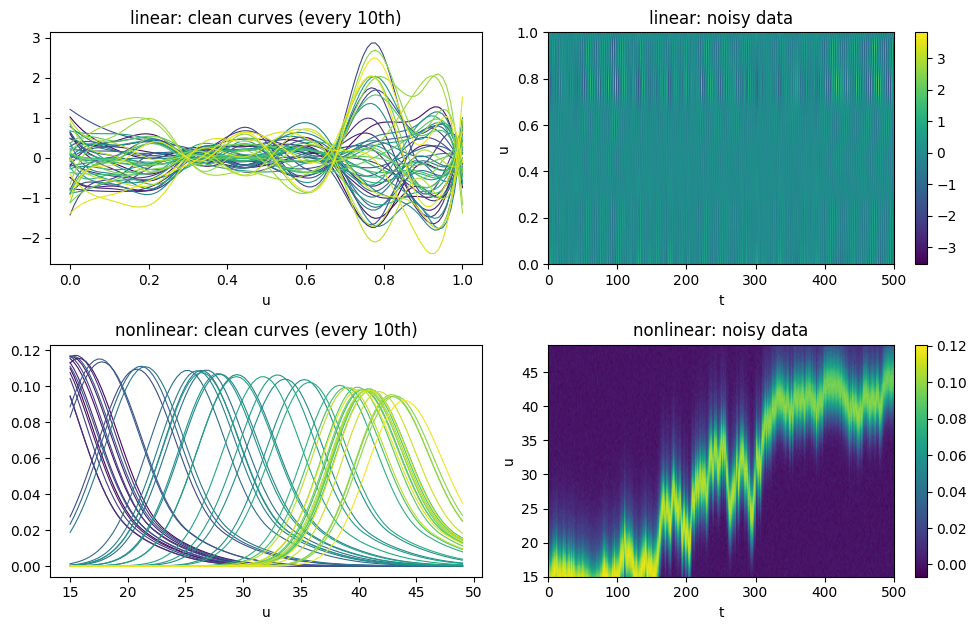

In [5]:
for s in SCENARIOS:
    sds = [sc.simulate(sc.SimCfg(seed=q, **{**SIM_DESIGNS[s], "meas_noise_sd": 0.0}))[1].std() for q in range(40001, 40006)]
    print(s, "curve sd:", round(np.median(sds), 4), "noise sd:", SIM_DESIGNS[s]["meas_noise_sd"])

fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
for r, s in enumerate(SCENARIOS):
    u, Xc, Xn = sc.simulate(sc.SimCfg(seed=EVAL_SEEDS[0], **SIM_DESIGNS[s]))
    cm = plt.cm.viridis(np.linspace(0, 1, Xc.shape[0]))
    for t in range(0, Xc.shape[0], 10):
        axes[r, 0].plot(u, Xc[t], color=cm[t], lw=0.8)
    axes[r, 0].set(title=f"{s}: clean curves (every 10th)", xlabel="u")
    im = axes[r, 1].imshow(Xn.T, aspect="auto", origin="lower", cmap="viridis", extent=[0, Xn.shape[0], u[0], u[-1]])
    axes[r, 1].set(title=f"{s}: noisy data", xlabel="t", ylabel="u")
    fig.colorbar(im, ax=axes[r, 1])
fig.tight_layout()
fig.savefig("example_curves.pdf", bbox_inches="tight")
plt.show()

In [6]:
# share of the variation over time that is random (variance across replications / total variance)
def stochastic_share(D, seeds=range(40001, 40021)):
    X = np.stack([sc.simulate(sc.SimCfg(seed=q, **{**D, "meas_noise_sd": 0.0}))[1] for q in seeds])
    return X.var(0).mean() / X.reshape(-1, X.shape[2]).var(0).mean()

for s in SCENARIOS:
    print(s, round(stochastic_share(SIM_DESIGNS[s]), 3))
print("nonlinear, trend only:", round(stochastic_share(dict(shift_scale=0.50, peak_width=0.10, trend_mode="det", meas_noise_sd=0.0017)), 3))

linear 0.953


nonlinear 0.593


nonlinear, trend only: 0.031


## Run

In [7]:
def run_tasks(tasks, n_workers=N_WORKERS):
    # runs run_cell.py in parallel, skips results that already exist
    env = dict(os.environ, PYTHONPATH=os.getcwd(), OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
    todo = [(s, o) for s, o in tasks if not os.path.exists(o)]
    print(len(tasks) - len(todo), "cached,", len(todo), "to run")
    t0 = time.time()
    running = []
    while todo or running:
        while todo and len(running) < n_workers:
            s, o = todo.pop(0)
            os.makedirs(os.path.dirname(o), exist_ok=True)
            json.dump(s, open(o + ".spec", "w"))
            p = subprocess.Popen([sys.executable, "run_cell.py", o + ".spec", o], env=env,
                                 stdout=open(o + ".log", "w"), stderr=subprocess.STDOUT)
            running.append((p, o))
        time.sleep(3)
        for p, o in list(running):
            if p.poll() is not None:
                running.remove((p, o))
                if p.returncode != 0:
                    print("FAILED", o, open(o + ".log").read()[-500:])
    print(f"done in {(time.time() - t0) / 60:.1f} min")


def load_rows(pattern):
    rows = []
    for f in sorted(glob.glob(pattern)):
        J = json.load(open(f))
        for r in J["rows"]:
            r.update(cand=J["spec"].get("cand"))
            rows.append(r)
    return pd.DataFrame(rows)


# FAE tuning on the pilot seeds (nonlinear data), set to True to redo it
RUN_TUNING = False
if RUN_TUNING:
    tasks = [(dict(sim=SIM_DESIGNS["nonlinear"], fae=f, K=K, B=B, seeds=PILOT_SEEDS, chunk=len(PILOT_SEEDS), cand=c),
              f"tuning/nonlinear/{c}_K{K}_B{B}.json")
             for c, f in FAE_CANDIDATES.items() for K in K_GRID for B in B_GRID]
    run_tasks(tasks)
    tune = load_rows("tuning/nonlinear/*_K*_B*.json")
    tune["score"] = np.log(tune.FAE_recon) + np.log(tune.FAE_fore)
    best = tune.groupby(["K", "B", "cand"]).score.mean().unstack("cand").idxmin(axis=1)
    FAE_CHOICE = {f"{K},{B}": c for (K, B), c in best.items()}
    print(FAE_CHOICE)

In [8]:
tasks = []
for s in SCENARIOS:
    for K in K_GRID:
        for B in B_GRID:
            cand = FAE_CHOICE[f"{K},{B}"]
            for j in range(0, R, CHUNK):
                spec = dict(sim=SIM_DESIGNS[s], fae=FAE_CANDIDATES[cand], K=K, B=B, seeds=EVAL_SEEDS[j:j + CHUNK],
                            chunk=CHUNK, cand=cand, scenario=s)
                tasks.append((spec, f"sim_results/{s}/K{K}_B{B}_part{j // CHUNK}.json"))
run_tasks(tasks)

both = {}
for s in SCENARIOS:
    d = load_rows(f"sim_results/{s}/K*_B*_part*.json")
    both[s] = d[d.seed.isin(EVAL_SEEDS)].reset_index(drop=True)
    print(s, len(both[s]), "rows")
pd.concat([v.assign(scenario=k) for k, v in both.items()]).to_csv(f"sim_results_both_R{R}.csv", index=False)

0 cached, 120 to run


done in 24.0 min
linear 1500 rows
nonlinear 1500 rows


## Tables

In [9]:
cap1 = ("Reconstruction accuracy of FPCA and FAE under the linear and nonlinear amplitude--phase simulation benchmarks. "
        "Entries report the relMSE across 100 simulation replications, with standard deviations in parentheses.")
cap2 = ("Out-of-sample forecasting accuracy of FPCA+VAR and FAE+VAR under the linear and nonlinear amplitude--phase simulation "
        "benchmarks. Entries report the relMSE across 100 simulation replications, with standard deviations in parentheses. "
        "Forecasting errors are evaluated over the five held-out curves.")
tab1 = post.paper_table(both, "recon", cap1, "tab:sim_fae_fpca")
tab2 = post.paper_table(both, "fore", cap2, "tab:sim_fae_fpca2")
open("table_recon.tex", "w").write(tab1)
open("table_forecast.tex", "w").write(tab2)
print(tab1)
print()
print(tab2)

\begin{table}[!t]
\centering
\caption{Reconstruction accuracy of FPCA and FAE under the linear and nonlinear amplitude--phase simulation benchmarks. Entries report the relMSE across 100 simulation replications, with standard deviations in parentheses.}
\label{tab:sim_fae_fpca}
\scriptsize
\setlength{\tabcolsep}{3pt}
\renewcommand{\arraystretch}{1.1}
\begin{tabular}{@{}llcccccc@{}}
\toprule
\multirow{2}{*}{Scenario} & \multirow{2}{*}{$B$} & \multicolumn{2}{c}{$K=3$} & \multicolumn{2}{c}{$K=5$} & \multicolumn{2}{c}{$K=7$} \\
\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}
& & FPCA & FAE & FPCA & FAE & FPCA & FAE \\
\midrule
\multirow{5}{*}{Linear} & $10$ & 0.0452 (0.0288) & 0.0453 (0.0288) & 0.0289 (0.0224) & 0.0291 (0.0224) & 0.0290 (0.0224) & 0.0291 (0.0224) \\
 & $20$ & 0.0178 (0.0164) & 0.0180 (0.0163) & 0.0003 (0.0002) & 0.0006 (0.0004) & 0.0004 (0.0003) & 0.0006 (0.0003) \\
 & $30$ & 0.0178 (0.0164) & 0.0178 (0.0163) & 0.0003 (0.0002) & 0.0003 (0.0002) & 0.0004 (0.0003) & 0.

In [10]:
# share of replications where FPCA has the smaller error
wins = []
for s, d in both.items():
    for (K, B), g in d.groupby(["K", "B"]):
        wins.append(dict(scenario=s, K=K, B=B, recon=(g.FPCA_recon < g.FAE_recon).mean(), fore=(g.FPCA_fore < g.FAE_fore).mean()))
wins = pd.DataFrame(wins)
wins.to_csv("fpca_win_rates.csv", index=False)
wins.pivot_table(index=["scenario", "B"], columns="K", values=["recon", "fore"]).round(2)

fore             recon           
K                3     5     7     3    5     7
scenario  B                                    
linear    10  0.58  0.55  0.55  0.75  1.0  0.79
          20  0.55  0.61  0.55  0.87  1.0  0.83
          30  0.57  0.57  0.51  0.67  1.0  0.49
          40  0.59  0.50  0.54  0.76  1.0  0.37
          50  0.60  0.52  0.48  0.66  1.0  0.30
nonlinear 10  0.06  0.21  0.37  0.00  0.0  0.02
          20  0.08  0.20  0.26  0.00  0.0  0.00
          30  0.07  0.14  0.25  0.00  0.0  0.00
          40  0.08  0.21  0.28  0.00  0.0  0.00
          50  0.05  0.14  0.29  0.00  0.0  0.00

## Figures

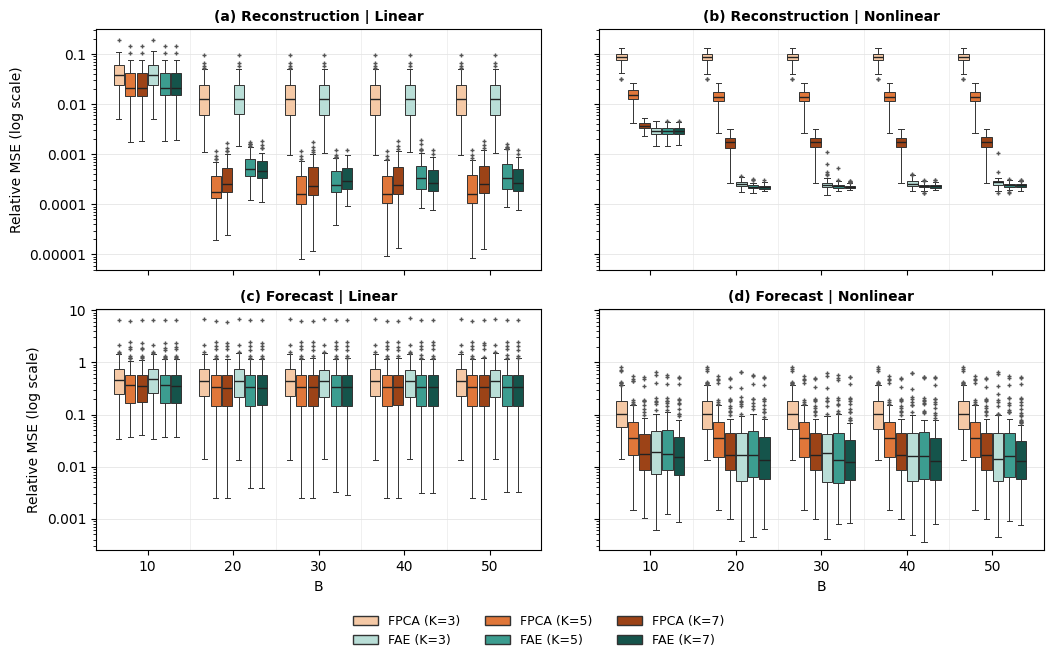

In [11]:
fig = post.paper_boxplot(both, K_GRID, B_GRID, logy=True)
post.finish_figure(fig, True, "boxplots_relMSE_log")
plt.show()

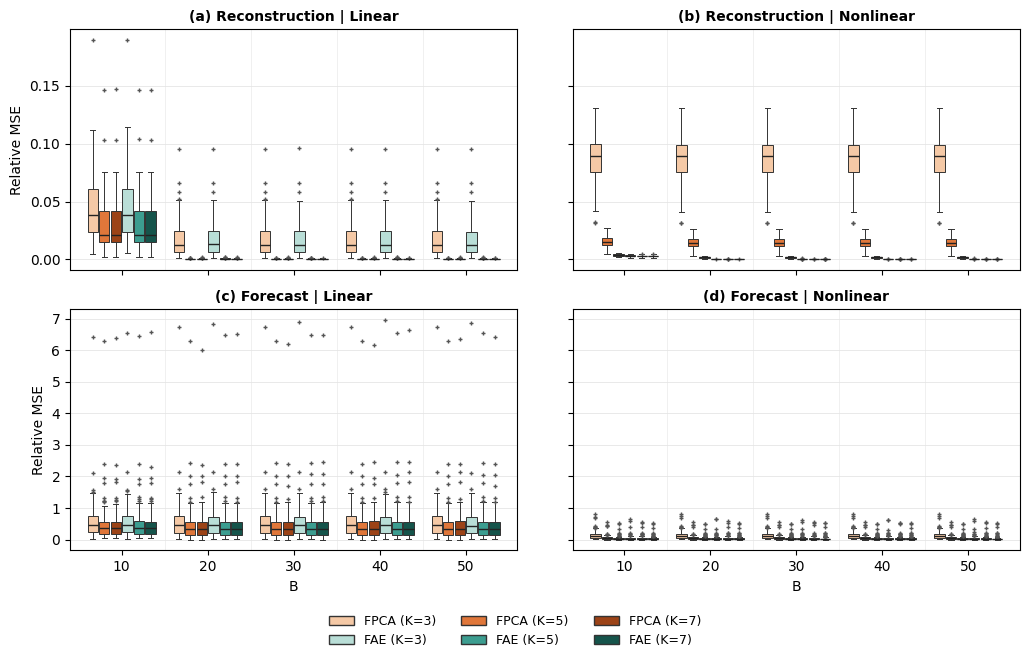

In [12]:
fig = post.paper_boxplot(both, K_GRID, B_GRID, logy=False)
post.finish_figure(fig, False, "boxplots_relMSE_nolog")
plt.show()

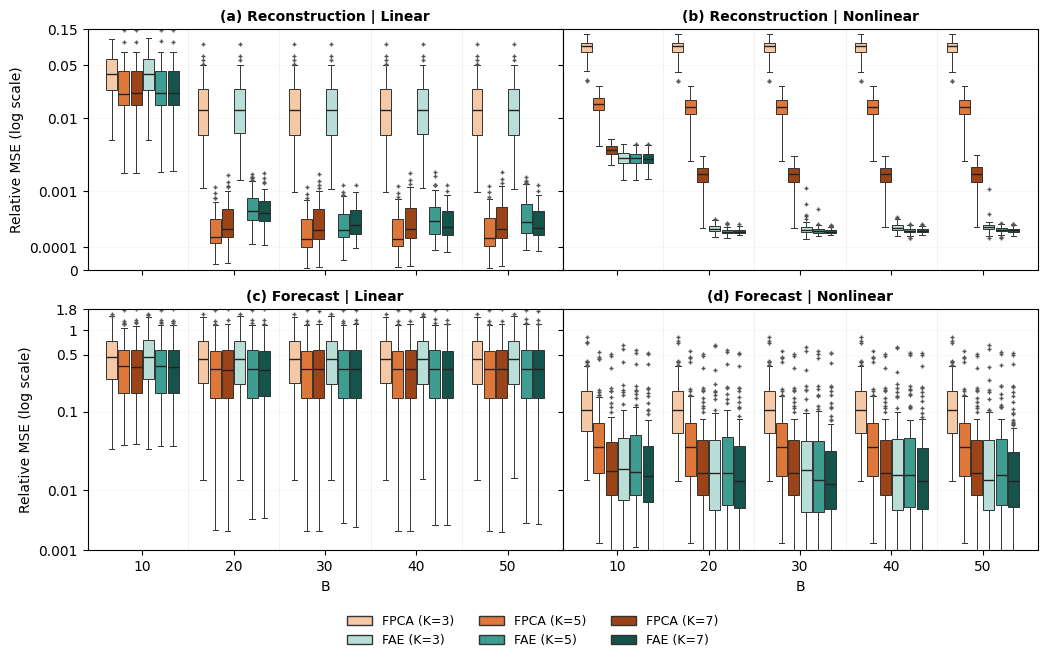

In [13]:
# log axis starting at 0 (recon) and 0.001 (forecast)
fig = post.shiftlog_figure(both, K_GRID, B_GRID, "boxplots_relMSE_shiftlog")
plt.show()